# 04 - MODEL TRAINING

#### El objetivo de este notebook es entrenar modelos de Machine Learning para predecir la categoría de ventas. Es decir, clasificar los productos en su clase.
#### 

### 1. Importamos librerias.

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score

import joblib
import sys

sys.path.append("..")

from src.config import PROCESSED_DATA_PATH, PROJECT_ROOT
from src.data_loader import load_csv

### 2. Cargamos el dataset limpio.

In [54]:
df = load_csv(PROCESSED_DATA_PATH)
df.head()

,title,rating,number_of_reviews,bought_in_last_month,current_discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,...,sustainability_badges,collected_at,coupon_discount_value,coupon_discount_type,discount_amount,discount_percentage,title_length,title_word_count,has_free_delivery,has_fastest_delivery
0,BOYA BOYALINK 2 Wireless Lavalier Microphone f...,4.6,375.0,300.0,89.68,NaN,159.00,0,1,1,...,1,2025-08-21 11:14:29,15.0,percentage,69.32,43.60,199,30,0,0
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Ch...",4.3,2457.0,6000.0,9.99,NaN,15.99,0,1,0,...,0,2025-08-21 11:14:29,NaN,no_coupon,6.00,37.52,200,34,0,0
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wirel...",4.6,3044.0,2000.0,314.00,NaN,349.00,0,1,0,...,0,2025-08-21 11:14:29,NaN,no_coupon,35.00,10.03,193,29,0,0
3,"Apple AirPods Pro 2 Wireless Earbuds, Active N...",4.6,35882.0,10000.0,NaN,162.24,NaN,1,0,0,...,0,2025-08-21 11:14:29,NaN,no_coupon,NaN,NaN,194,24,0,0
4,Apple AirTag 4 Pack. Keep Track of and find Yo...,4.8,28988.0,10000.0,NaN,72.74,NaN,0,0,0,...,0,2025-08-21 11:14:29,NaN,no_coupon,NaN,NaN,133,24,0,0


In [55]:
df.shape

(42675, 21)

In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   title                     42675 non-null  str    
 1   rating                    41651 non-null  float64
 2   number_of_reviews         41651 non-null  float64
 3   bought_in_last_month      32164 non-null  float64
 4   current_discounted_price  30926 non-null  float64
 5   price_on_variant          20071 non-null  float64
 6   listed_price              12311 non-null  float64
 7   is_best_seller            42675 non-null  int64  
 8   is_sponsored              42675 non-null  int64  
 9   is_couponed               42675 non-null  int64  
 10  buy_box_availability      42675 non-null  int64  
 11  sustainability_badges     42675 non-null  int64  
 12  collected_at              42675 non-null  str    
 13  coupon_discount_value     1948 non-null   float64
 14  coupon_discount_t

In [57]:
# 'collected_at' se carga como texto
df["collected_at"] = pd.to_datetime(df["collected_at"], errors='coerce')

### 3. Creamos `sales_category` ya que antes no la hemos guardado.

In [58]:
def classify_sales(value):
    if pd.isna(value):
        return np.nan
    elif value <= 100:
        return "low"
    elif value <= 1000:
        return "medium"
    elif value <= 10000:
        return "high"
    else:
        return "very_high"
    
df["sales_category"] = df["bought_in_last_month"].apply(classify_sales)

In [59]:
df["sales_category"].value_counts(dropna=False)

sales_category
medium       15032
low          14768
NaN          10511
high          1430
very_high      934
Name: count, dtype: int64

### 4. Eliminamos las filas que no tienen la variable objetivo.

In [60]:
df_model =df.dropna(subset=["sales_category"]).copy()


In [61]:
df_model.shape

(32164, 22)

### 5. Seleccionamos y definimos las variables predictoras y la variable objetivo.

In [62]:
features = [
    "rating",
    "number_of_reviews",
    "current_discounted_price",
    "price_on_variant",
    "listed_price",
    "is_best_seller",
    "is_sponsored",
    "is_couponed",
    "buy_box_availability",
    "sustainability_badges",
    "coupon_discount_value",
    "discount_amount",
    "discount_percentage",
    "title_length",
    "title_word_count",
    "has_free_delivery",
    "has_fastest_delivery"
]

target = "sales_category"

In [63]:
X = df_model[features]
y = df_model[target]

### 6. Tratamos los nulos.

In [64]:
X.isna().sum().sort_values(ascending=False)

coupon_discount_value       31043
discount_amount             21449
listed_price                21449
discount_percentage         21449
price_on_variant            16962
current_discounted_price     6927
rating                         76
number_of_reviews              76
is_best_seller                  0
buy_box_availability            0
is_couponed                     0
is_sponsored                    0
sustainability_badges           0
title_length                    0
title_word_count                0
has_free_delivery               0
has_fastest_delivery            0
dtype: int64

In [65]:
X = X.fillna(0)

print(f"Número de nulos totales: {X.isna().sum().sum()}")

Número de nulos totales: 0


### 7. Separamos las filas en train y test.

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [67]:
y_train.value_counts(normalize=True)

sales_category
medium       0.467374
low          0.459135
high         0.044460
very_high    0.029031
Name: proportion, dtype: float64

In [68]:
y_test.value_counts(normalize=True)

sales_category
medium       0.467278
low          0.459195
high         0.044458
very_high    0.029069
Name: proportion, dtype: float64

### 8. Entrenamos un modelo baseline (tonto) para tener una referencia mínima.

In [69]:
baseline_model = DummyClassifier(strategy="most_frequent", random_state=42)

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

print("Accuracy baseline: ", accuracy_score(y_test, y_pred_baseline))
print()
print(classification_report(y_test, y_pred_baseline))

Accuracy baseline:  0.4672780973107415

              precision    recall  f1-score   support

        high       0.00      0.00      0.00       286
         low       0.00      0.00      0.00      2954
      medium       0.47      1.00      0.64      3006
   very_high       0.00      0.00      0.00       187

    accuracy                           0.47      6433
   macro avg       0.12      0.25      0.16      6433
weighted avg       0.22      0.47      0.30      6433



c:\Users\mforq\Dropbox\PC\Documents\EVOLVE\EDA_ML_amazon_products\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\mforq\Dropbox\PC\Documents\EVOLVE\EDA_ML_amazon_products\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\mforq\Dropbox\PC\Documents\EVOLVE\EDA_ML_amazon_products\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` 

### 9. Entrenamos un modelo real: Random Forest.

In [70]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced", n_jobs=1)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Accuracy Random Forest: ", accuracy_score(y_test, y_pred_rf))
print()
print(classification_report(y_test, y_pred_rf))

Accuracy Random Forest:  0.9207212808953832

              precision    recall  f1-score   support

        high       0.56      0.65      0.60       286
         low       0.95      0.95      0.95      2954
      medium       0.93      0.91      0.92      3006
   very_high       0.97      0.95      0.96       187

    accuracy                           0.92      6433
   macro avg       0.85      0.87      0.86      6433
weighted avg       0.92      0.92      0.92      6433



### El modelo Random Forest obtiene un accuracy del 92,07%. Además, el macro avg f1-score alcanza un valor de 0.86, lo que indica que el modelo mejora en las clases mayoritarias y consigue un rendimineto razonable en las clases minoritarias respecto al modelo base.
### Las clases `low`, `medium` y `very_high` obtienen resultados muy buenos. Sin embargo, `high` obtiene un rendimiento muy inferior. Esto quiere decir que el modelo tiene más dificultades para distinguir los productos de esta clase.
### El modelo muestra capacidad para aprender patrones relevantes especialmente en variables como visibilidad, reseñas o precio.
###

### 10. Matriz de confusión.

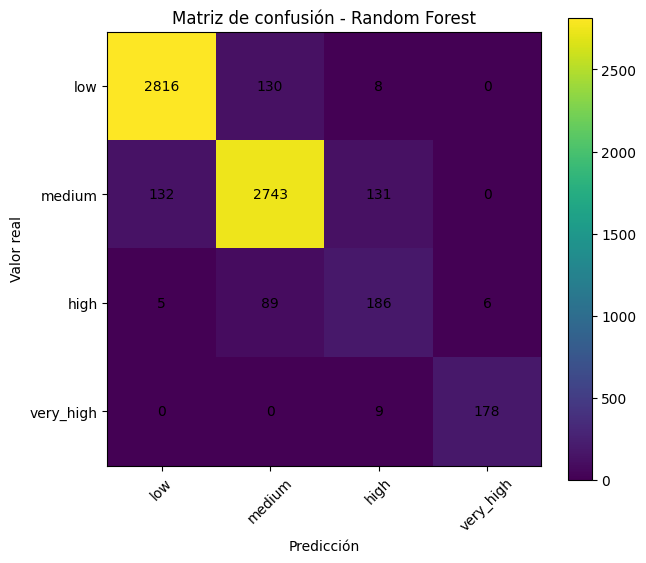

In [71]:
labels = ["low", "medium", "high", "very_high"]

cm = confusion_matrix(y_test, y_pred_rf, labels=labels)

plt.figure(figsize=(7,6))
plt.imshow(cm)
plt.colorbar()

plt.xticks(range(len(labels)), labels, rotation=45)
plt.yticks(range(len(labels)), labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.title("Matriz de confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor real")

plt.show()


### La matriz de confusión confirma que el modelo Random Forest clasifica correctamente la mayoría de productos de las categorías `low`, `medium` y `very_high`. 
### La categoría `high`es la más problemática clasificando 186 correctamente pero confundiendo 89 con la categoría `medium`. Esto indica que los productos de la categoría `high` y `medium` comparten características, lo que hace que sean difíciles de separar.
###

### 11. Observamos la importancia de las variables.

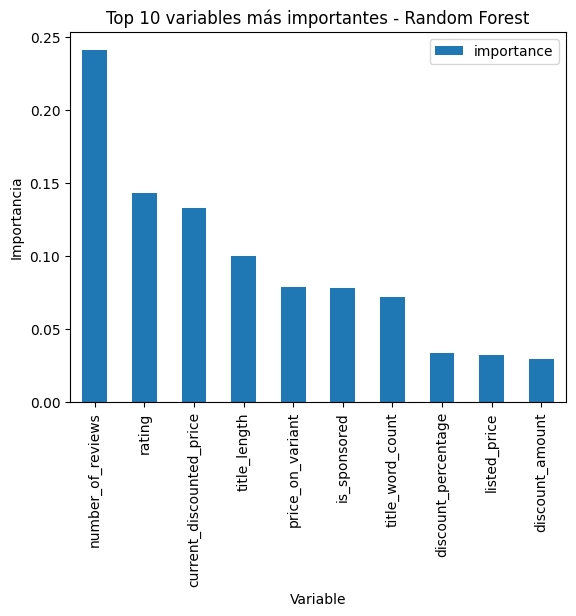

In [72]:
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_
}).sort_values(by="importance", ascending=False)

feature_importance.head(10).plot(x="feature", y="importance", kind="bar")

plt.title("Top 10 variables más importantes - Random Forest")
plt.xlabel("Variable")
plt.ylabel("Importancia")
plt.show()

### El análisis de importancia de variables del Random Forest muestra que `number_of_reviews` es la variable más relevante para predecir la categoría de ventas.
###

### 12. Entrenamos otro modelo: Gradient Bosting.

In [73]:
# Tratamos el desbalanceo de datos
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Entrenamos el modelo
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train, sample_weight=sample_weights)
y_pred_gb = gb_model.predict(X_test)

# Evaluamos el modelo
print("Accuracy Gradient Boosting:", accuracy_score(y_test, y_pred_gb))
print()
print(classification_report(y_test, y_pred_gb))

Accuracy Gradient Boosting: 0.8394217316959428

              precision    recall  f1-score   support

        high       0.32      0.79      0.45       286
         low       0.89      0.92      0.90      2954
      medium       0.92      0.76      0.83      3006
   very_high       0.96      0.97      0.97       187

    accuracy                           0.84      6433
   macro avg       0.77      0.86      0.79      6433
weighted avg       0.88      0.84      0.85      6433



### Se puede apreciar que igual que el modelo Random Forest, la categoría `high` es la que peor clasifica. Tiene un recall bastante alto, lo que indica que el modelo encuentra gran cantidad de productos de la categoría `high` pero predice muchos productos como `high` que no lo son, es decir, falsos positivos.
### 

### 13. Matriz de confusión.

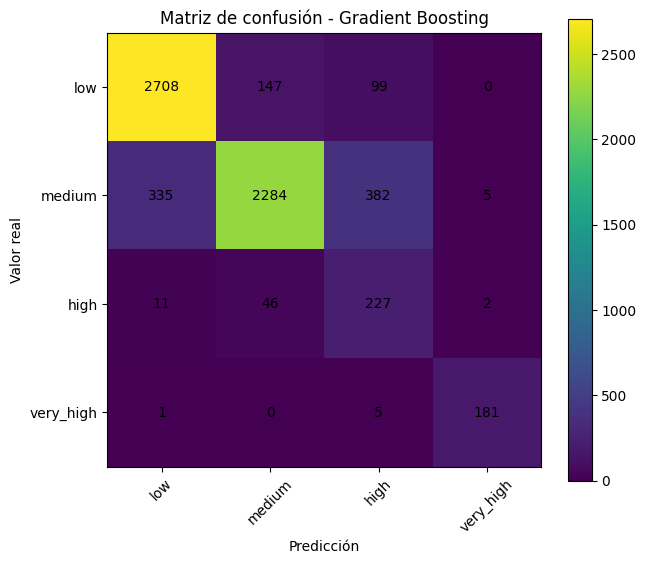

In [74]:
labels = ["low", "medium", "high", "very_high"]

cm_gb = confusion_matrix(y_test, y_pred_gb, labels=labels)

plt.figure(figsize=(7,6))
plt.imshow(cm_gb)
plt.colorbar()

plt.xticks(range(len(labels)), labels, rotation=45)
plt.yticks(range(len(labels)), labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, cm_gb[i, j], ha='center', va='center')

plt.title("Matriz de confusión - Gradient Boosting")
plt.xlabel("Predicción")
plt.ylabel("Valor real")

plt.show()

### Se puede apreciar que Gradient Boosting detecta más `high`, pero se equivoca más al predecir `high`. En cambio, Random Forest predice high con más equilibrio.
###

### 14. Observamos la importancia de las variables.

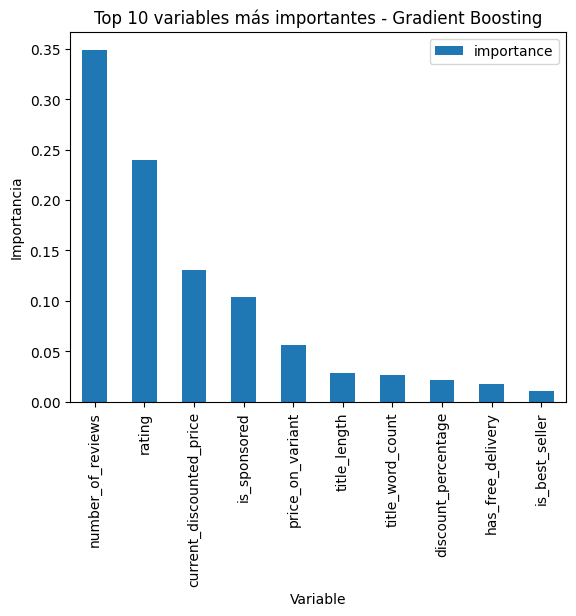

In [75]:
gb_feature_importance = pd.DataFrame({
    "feature": features,
    "importance": gb_model.feature_importances_
}).sort_values(by="importance", ascending=False)

gb_feature_importance.head(10).plot(x="feature", y="importance", kind="bar")

plt.title("Top 10 variables más importantes - Gradient Boosting")
plt.xlabel("Variable")
plt.ylabel("Importancia")
plt.show()

### De la misma manera que en el modelo Random Forest, la variable más importante en la clasificación es la visibilidad.
###

### 15. Comparación simple con el modelo Random Forest.

In [76]:
model_comparison = pd.DataFrame({
    "model": ["Baseline", "Random Forest", "Gradient Boosting"],
    "accuracy": [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb)
    ]
})

model_comparison

,model,accuracy
0,Baseline,0.467278
1,Random Forest,0.920721
2,Gradient Boosting,0.839422


### El modelo Random Forest clasifica con más precisión que el modelo Gradient Boosting. Además, tiene un rendimiento más equilibrado entre categorías.
### Ambos modelos coinciden en la importancia de variables como `number_of_reviews` o `rating` y en que la categoría más dificil de predecir es `high`.
### 

### 16. Optimización del modelo Random Forest.

In [77]:
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
    "class_weight": ["balanced", "balanced_subsample"]
}

rf_base = RandomForestClassifier(random_state=42, n_jobs=1)

random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=20,
    scoring="f1_macro",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=1
)

# Entrenamos
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END class_weight=balanced, max_depth=30, max_features=None, min_samples_leaf=4, min_samples_split=2, n_estimators=500; total time=  14.0s
[CV] END class_weight=balanced, max_depth=30, max_features=None, min_samples_leaf=4, min_samples_split=2, n_estimators=500; total time=  14.1s
[CV] END class_weight=balanced, max_depth=30, max_features=None, min_samples_leaf=4, min_samples_split=2, n_estimators=500; total time=  14.4s
[CV] END class_weight=balanced_subsample, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   1.4s
[CV] END class_weight=balanced_subsample, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   1.4s
[CV] END class_weight=balanced_subsample, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   1.5s
[CV] END class_weight=balanced_subsample, 

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'class_weight': ['balanced', 'balanced_subsample'], 'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can b

In [79]:
random_search.best_params_

{'n_estimators': 500,
 'min_samples_split': 5,
 'min_samples_leaf': 2,
 'max_features': 'sqrt',
 'max_depth': 40,
 'class_weight': 'balanced_subsample'}

In [81]:
print(random_search.best_score_)

0.858609558129381


### 17. Evaluamos el mejor modelo optimizado.

In [83]:
# Mejor modelo
best_rf_model = random_search.best_estimator_

# Predecimos
y_pred_best_rf = best_rf_model.predict(X_test)

# Evaluamos
print("Accuracy Optimized Random Forest:", accuracy_score(y_test, y_pred_best_rf))
print("Macro F1 Optimized Random Forest:", f1_score(y_test, y_pred_best_rf, average="macro"))
print(classification_report(y_test, y_pred_best_rf))

Accuracy Optimized Random Forest: 0.9238302502720348
Macro F1 Optimized Random Forest: 0.8672623425883609
              precision    recall  f1-score   support

        high       0.62      0.64      0.63       286
         low       0.95      0.95      0.95      2954
      medium       0.92      0.92      0.92      3006
   very_high       0.99      0.94      0.97       187

    accuracy                           0.92      6433
   macro avg       0.87      0.86      0.87      6433
weighted avg       0.92      0.92      0.92      6433



### El modelo optimizado ha mejorado ligeramente la precisión y el f1_score, y mantiene un recall parecido pero en rasgos general obtiene unos resultados muy parecidos al RandomForest.
###

### 18. Matriz de confusión.

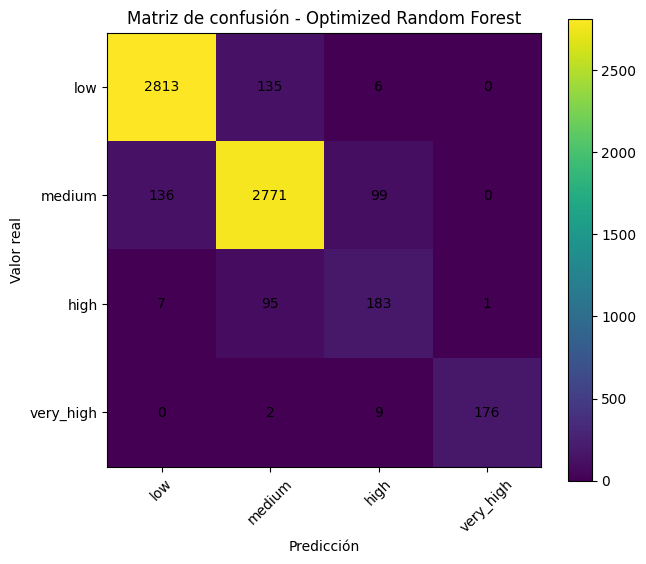

In [84]:
labels = ["low", "medium", "high", "very_high"]

cm_best_rf = confusion_matrix(y_test, y_pred_best_rf, labels=labels)

plt.figure(figsize=(7, 6))
plt.imshow(cm_best_rf)
plt.colorbar()

plt.xticks(range(len(labels)), labels, rotation=45)
plt.yticks(range(len(labels)), labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, cm_best_rf[i, j], ha="center", va="center")

plt.title("Matriz de confusión - Optimized Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

### 19. Comparación de modelos.

In [85]:
model_comparison = pd.DataFrame({
    "model": [
        "Baseline",
        "Random Forest",
        "Gradient Boosting",
        "Optimized Random Forest"
    ],
    "accuracy": [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_best_rf)
    ],
    "macro_f1": [
        f1_score(y_test, y_pred_baseline, average="macro"),
        f1_score(y_test, y_pred_rf, average="macro"),
        f1_score(y_test, y_pred_gb, average="macro"),
        f1_score(y_test, y_pred_best_rf, average="macro")
    ],
    "weighted_f1": [
        f1_score(y_test, y_pred_baseline, average="weighted"),
        f1_score(y_test, y_pred_rf, average="weighted"),
        f1_score(y_test, y_pred_gb, average="weighted"),
        f1_score(y_test, y_pred_best_rf, average="weighted")
    ]
})

model_comparison

,model,accuracy,macro_f1,weighted_f1
0,Baseline,0.467278,0.159233,0.297624
1,Random Forest,0.920721,0.858062,0.921924
2,Gradient Boosting,0.839422,0.788556,0.851443
3,Optimized Random Forest,0.923830,0.867262,0.924112


### El mejor modelo es el Random Forest Optimizado, superando ligeramente el rendimiento del modelo Random Forest que ya obtenía un resultado muy bueno.
###

### 20. Guardamos el mejor modelo.

In [88]:
MODEL_PATH = PROJECT_ROOT / "models" / "optimized_random_forest.pkl"

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(features, MODEL_PATH)

print(f"Modelo guardado en {MODEL_PATH}")

Modelo guardado en c:\Users\mforq\Dropbox\PC\Documents\EVOLVE\EDA_ML_amazon_products\models\optimized_random_forest.pkl


### 21. Guardamos las variables utilizadas.

In [90]:
FEATURES_PATH = PROJECT_ROOT / "models" / "features.pkl"

joblib.dump(features, FEATURES_PATH)

print(f"Features guardadas en {FEATURES_PATH}")

Features guardadas en c:\Users\mforq\Dropbox\PC\Documents\EVOLVE\EDA_ML_amazon_products\models\features.pkl


## En este notebook, se han entrenado y comparado diferentes modelos de clasificación para predecir la categoría de ventas de los productos del dataset.
## Hemos podido observar que el model Random Forest ha sido el modelo más balanceado a la hora de clasificar categorías, siendo `high` la más complicada para todos los modelos. Tras realizar la optimización del Random Forest, hemos obtenido resultados ligeramente mejores haciendo que sea el mejor modelo analizado en este notebook.
## También, se ha observado como la visibilidad o el rating son las variables más importantes a la hora de predecir el precio de los productos.
## Por último, se ha guardado tanto el modelo como las features para un posible futuro uso.